## RetailTech E-Commerce — EDA Notebook
# STEP 1 — Data Loading

In [7]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [8]:
BASE = '/Users/mohamedarshad/Desktop/NIIT/DataAnalysis-Project/ProjectData'

customer_dataset       = pd.read_excel(f'{BASE}/Customers_dataset.xlsx')
geolocation_dataset    = pd.read_excel(f'{BASE}/Geolocation_dataset.xlsx')
Order_items_dataset    = pd.read_excel(f'{BASE}/Order_items_dataset.xlsx')
Order_reviews_dataset  = pd.read_excel(f'{BASE}/Order_reviews_dataset.xlsx')
Orders_dataset         = pd.read_excel(f'{BASE}/Orders_dataset.xlsx')
Products_dataset       = pd.read_excel(f'{BASE}/Products_dataset.xlsx')

print(" All 6 datasets loaded successfully.")

 All 6 datasets loaded successfully.


### Step 1 — Null Handling 


In [9]:
# All datasets null check

# customer_dataset        → 0 Null
# geolocation_dataset     → 1 Null (geolocation_city) - done
# Order_items_dataset     → 0 Null
# Order_reviews_dataset   → review_comment_message (40850 - replaced with no comments  , review_date (47554) - NAT

# Orders_dataset          → order_approved_at (5048), order_delivered_shipping_date (5048),
#                           order_delivered_customer_date (8028), order_estimated_delivery_date (5048)
#                           NOTE: All nulls belong to CANCELLED orders — expected behaviour

# Products_dataset        → 0 Null





In [10]:
geolocation_dataset.isnull().sum()



geolocation_zip_code    0
geolocation_city        1
geolocation_state       0
geolocation_lat         0
geolocation_lng         0
region                  0
dtype: int64

In [11]:
# CHECKING WHERE THE NONE IS LOCATED
geolocation_dataset = geolocation_dataset[geolocation_dataset['geolocation_city'].isnull()] 

# FILLED THE EMPTY VALUE AS None -> 'Noney'
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].fillna("Noney") 

# CHANGING TEXT DATA INTO DATETIME DATA & errors='coerce' -> IF THERE IS ANY NULL , INVALID , EMPTY DATA IS PRESENT IT CHANGES THEM INTO NaT
Order_reviews_dataset['review_date'] = pd.to_datetime(Order_reviews_dataset['review_date'], errors='coerce')  


In [12]:
Orders_dataset[Orders_dataset["order_approved_at"].isnull()]['order_status'].value_counts()

order_status
cancelled    5048
Name: count, dtype: int64

In [13]:
# Cancelled orders have null approval/shipping/delivery dates — confirmed below
Orders_dataset[Orders_dataset["order_approved_at"].isnull()]["order_status"].value_counts()

order_status
cancelled    5048
Name: count, dtype: int64

In [14]:
# Filling missing review comments with 'No Comment'
Order_reviews_dataset['review_comment_message'] = (
    Order_reviews_dataset['review_comment_message']
    .fillna('No Comment')
)
print("review_comment_message nulls filled with 'No Comment'")

review_comment_message nulls filled with 'No Comment'


---
## STEP 2 — Basic Data Exploration
> For each dataset: `.shape`, `.info()`, `.head()`, `.isnull().sum()`, `.describe()`  
> Then column-type segregation: **Numerical | Categorical | Datetime**

In [15]:
def explore_dataset(df, name):

    """
    Here we are Displaying a complete exploratory summary of a DataFrame.
    Includes:
    - Shape
    - Data types
    - First 3 rows
    - Missing values
    - Column type segregation
    - Descriptive statistics
    """

    separator = "=" * 70

    print("\n" + separator)
    print(f"DATASET : {name}")
    print(separator)

    # Shape
    print("\nShape")
    print("-" * 70)
    print(f"Rows    : {df.shape[0]:,}")
    print(f"Columns : {df.shape[1]}")

    # Info
    print("\nInformation")
    print("-" * 70)
    df.info()

    # Head
    print("\nFirst 3 Rows")
    print("-" * 70)
    print(df.head(3))

    # Missing Values
    print("\nMissing Values")
    print("-" * 70)

    null_count = df.isnull().sum()
    null_percent = (df.isnull().mean() * 100).round(2)

    null_summary = pd.DataFrame({
        "Null Count": null_count,
        "Null Percentage": null_percent
    })

    null_summary = null_summary[null_summary["Null Count"] > 0]

    if null_summary.empty:
        print("No missing values found.")
    else:
        print(null_summary)

    # Column Types
    numerical = df.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical = df.select_dtypes(
        include=["object"]
    ).columns.tolist()

    datetime = df.select_dtypes(
        include=["datetime64[ns]"]
    ).columns.tolist()

    print("\nColumn Categories")
    print("-" * 70)
    print(f"Numerical   ({len(numerical)}): {numerical}")
    print(f"Categorical ({len(categorical)}): {categorical}")
    print(f"Datetime    ({len(datetime)}): {datetime}")

    print("\n" + separator)

---
### 2.1 — Customers Dataset

In [16]:
explore_dataset(customer_dataset, "Customers Dataset")


DATASET : Customers Dataset

Shape
----------------------------------------------------------------------
Rows    : 90,000
Columns : 5

Information
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        90000 non-null  object
 1   customer_zip_code  90000 non-null  int64 
 2   gender             90000 non-null  object
 3   age_group          90000 non-null  object
 4   customer_segment   90000 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.4+ MB

First 3 Rows
----------------------------------------------------------------------
  customer_id  customer_zip_code  gender age_group customer_segment
0      C00001             690511  Female     36-45            Loyal
1      C00002             509152    Male     26-35              New
2   

In [17]:
# ── Customers — Column Segregation (standalone view) ──────────────────────────
num_col  = customer_dataset.select_dtypes(exclude=["object"]).columns.tolist()
cat_col  = customer_dataset.select_dtypes(include=["object"]).columns.tolist()
date_col = customer_dataset.select_dtypes(include=["datetime"]).columns.tolist()

print(f"Numerical   : {num_col}")
print(f"Categorical : {cat_col}")
print(f"Datetime    : {date_col}")

Numerical   : ['customer_zip_code']
Categorical : ['customer_id', 'gender', 'age_group', 'customer_segment']
Datetime    : []


---
### 2.2 — Geolocation Dataset

In [18]:
explore_dataset(geolocation_dataset, "Geolocation Dataset")


DATASET : Geolocation Dataset

Shape
----------------------------------------------------------------------
Rows    : 1
Columns : 6

Information
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
Index: 1 entries, 49193 to 49193
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   geolocation_zip_code  1 non-null      int64  
 1   geolocation_city      1 non-null      object 
 2   geolocation_state     1 non-null      object 
 3   geolocation_lat       1 non-null      float64
 4   geolocation_lng       1 non-null      float64
 5   region                1 non-null      object 
dtypes: float64(2), int64(1), object(3)
memory usage: 56.0+ bytes

First 3 Rows
----------------------------------------------------------------------
       geolocation_zip_code geolocation_city geolocation_state  \
49193                795159            Noney           

In [19]:
# ── Geolocation — Column Segregation ─────────────────────────────────────────
num_col  = geolocation_dataset.select_dtypes(exclude=["object"]).columns.tolist()
cat_col  = geolocation_dataset.select_dtypes(include=["object"]).columns.tolist()
date_col = geolocation_dataset.select_dtypes(include=["datetime"]).columns.tolist()

print(f"Numerical   : {num_col}")
print(f"Categorical : {cat_col}")
print(f"Datetime    : {date_col}")

Numerical   : ['geolocation_zip_code', 'geolocation_lat', 'geolocation_lng']
Categorical : ['geolocation_city', 'geolocation_state', 'region']
Datetime    : []


---
### 2.3 — Products Dataset

In [20]:
explore_dataset(Products_dataset, "Products Dataset")


DATASET : Products Dataset

Shape
----------------------------------------------------------------------
Rows    : 32,951
Columns : 8

Information
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   product_id          32951 non-null  object
 1   Category_name       32951 non-null  object
 2   sub_category_name   32951 non-null  object
 3   product_weight_g    32951 non-null  int64 
 4   brand               32951 non-null  object
 5   cost_price          32951 non-null  int64 
 6   selling_price       32951 non-null  int64 
 7   stock_availability  32951 non-null  object
dtypes: int64(3), object(5)
memory usage: 2.0+ MB

First 3 Rows
----------------------------------------------------------------------
  product_id   Category_name    sub_category_name  product

In [21]:
# ── Products — Column Segregation ────────────────────────────────────────────
num_col  = Products_dataset.select_dtypes(exclude=["object"]).columns.tolist()
cat_col  = Products_dataset.select_dtypes(include=["object"]).columns.tolist()
date_col = Products_dataset.select_dtypes(include=["datetime"]).columns.tolist()

print(f"Numerical   : {num_col}")
print(f"Categorical : {cat_col}")
print(f"Datetime    : {date_col}")

Numerical   : ['product_weight_g', 'cost_price', 'selling_price']
Categorical : ['product_id', 'Category_name', 'sub_category_name', 'brand', 'stock_availability']
Datetime    : []


---
### 2.4 — Orders Dataset

In [22]:
# Parse all date columns in Orders dataset (DD/MM/YYYY format)
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_shipping_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_columns:
    Orders_dataset[col] = pd.to_datetime(Orders_dataset[col], dayfirst=True, errors='coerce')

print(" Date columns parsed. Dtypes after parsing:")
print(Orders_dataset[date_columns].dtypes)

 Date columns parsed. Dtypes after parsing:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_shipping_date    datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [23]:
explore_dataset(Orders_dataset, "Orders Dataset")


DATASET : Orders Dataset

Shape
----------------------------------------------------------------------
Rows    : 99,999
Columns : 9

Information
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99999 non-null  object        
 1   customer_id                    99999 non-null  object        
 2   order_status                   99999 non-null  object        
 3   payment_type                   99999 non-null  object        
 4   order_purchase_timestamp       99999 non-null  datetime64[ns]
 5   order_approved_at              94951 non-null  datetime64[ns]
 6   order_delivered_shipping_date  94951 non-null  datetime64[ns]
 7   order_delivered_customer_date  91971 non-null  datetime64[ns]
 8   

In [24]:
# ── Orders — Column Segregation ───────────────────────────────────────────────
num_col  = Orders_dataset.select_dtypes(exclude=["object", "datetime64[ns]"]).columns.tolist()
cat_col  = Orders_dataset.select_dtypes(include=["object"]).columns.tolist()
date_col = Orders_dataset.select_dtypes(include=["datetime64[ns]"]).columns.tolist()

print(f"Numerical   : {num_col}")
print(f"Categorical : {cat_col}")
print(f"Datetime    : {date_col}")

Numerical   : []
Categorical : ['order_id', 'customer_id', 'order_status', 'payment_type']
Datetime    : ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


---
### 2.5 — Order Items Dataset

In [25]:
explore_dataset(Order_items_dataset, "Order Items Dataset")


DATASET : Order Items Dataset

Shape
----------------------------------------------------------------------
Rows    : 150,000
Columns : 7

Information
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   order_item_id  150000 non-null  object 
 1   order_id       150000 non-null  object 
 2   quantity       150000 non-null  int64  
 3   product_id     150000 non-null  object 
 4   unit_price     150000 non-null  int64  
 5   discount(%)    150000 non-null  float64
 6   shipping_cost  150000 non-null  float64
dtypes: float64(2), int64(2), object(3)
memory usage: 8.0+ MB

First 3 Rows
----------------------------------------------------------------------
  order_item_id order_id  quantity product_id  unit_price  discount(%)  \
0      OI000001   O00001         1     P2

In [26]:
# ── Order Items — Column Segregation ─────────────────────────────────────────
num_col  = Order_items_dataset.select_dtypes(exclude=["object"]).columns.tolist()
cat_col  = Order_items_dataset.select_dtypes(include=["object"]).columns.tolist()
date_col = Order_items_dataset.select_dtypes(include=["datetime"]).columns.tolist()

print(f"Numerical   : {num_col}")
print(f"Categorical : {cat_col}")
print(f"Datetime    : {date_col}")

Numerical   : ['quantity', 'unit_price', 'discount(%)', 'shipping_cost']
Categorical : ['order_item_id', 'order_id', 'product_id']
Datetime    : []


---
### 2.6 — Order Reviews Dataset

In [27]:
# Parse review_date column
Order_reviews_dataset['review_date'] = pd.to_datetime(
    Order_reviews_dataset['review_date'], dayfirst=True, errors='coerce'
)
print(" review_date parsed. Dtype:", Order_reviews_dataset['review_date'].dtype)

 review_date parsed. Dtype: datetime64[ns]


In [28]:
explore_dataset(Order_reviews_dataset, "Order Reviews Dataset")


DATASET : Order Reviews Dataset

Shape
----------------------------------------------------------------------
Rows    : 97,019
Columns : 5

Information
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97019 entries, 0 to 97018
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   review_id               97019 non-null  object        
 1   order_id                97019 non-null  object        
 2   review_score            97019 non-null  int64         
 3   review_comment_message  97019 non-null  object        
 4   review_date             49465 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 3.7+ MB

First 3 Rows
----------------------------------------------------------------------
  review_id order_id  review_score              review_comment_message  \
0    R00001   O41195

In [29]:
# ── Order Reviews — Column Segregation ───────────────────────────────────────
num_col  = Order_reviews_dataset.select_dtypes(exclude=["object", "datetime64[ns]"]).columns.tolist()
cat_col  = Order_reviews_dataset.select_dtypes(include=["object"]).columns.tolist()
date_col = Order_reviews_dataset.select_dtypes(include=["datetime64[ns]"]).columns.tolist()

print(f"Numerical   : {num_col}")
print(f"Categorical : {cat_col}")
print(f"Datetime    : {date_col}")

Numerical   : ['review_score']
Categorical : ['review_id', 'order_id', 'review_comment_message']
Datetime    : ['review_date']


---
### STEP 2 :  SUMMARY — All Datasets Column Map

| Dataset | Rows | Numerical Cols | Categorical Cols | Datetime Cols |
|---------|------|----------------|-----------------|---------------|
| Customers | 90,000 | customer_zip_code | gender, age_group, customer_segment, customer_id | — |
| Geolocation | 155,545 | geolocation_zip_code, lat, lng | city, state, region | — |
| Products | 32,951 | product_weight_g, cost_price, selling_price | product_id, Category_name, sub_category_name, brand, stock_availability | — |
| Orders | 99,999 | — | order_id, customer_id, order_status, payment_type | purchase, approved, shipped, delivered, estimated |
| Order Items | 150,000 | quantity, unit_price, discount(%), shipping_cost | order_item_id, order_id, product_id | — |
| Order Reviews | 97,019 | review_score | review_id, order_id, review_comment_message | review_date |

---
## STEP 3 — Merging Datasets
> **Strategy:** `Order_items_dataset` is the base (grain = 1 line item per order).  
> We LEFT JOIN three datasets into it:
> 1. `Orders_dataset` → via `order_id` (adds status, payment, dates, customer_id)
> 2. `Customers_dataset` → via `customer_id` (adds gender, age_group, segment)
> 3. `Products_dataset` → via `product_id` (adds category, brand, cost & selling price)

### 3.1 — Merge Order Items ← Orders (on `order_id`)

In [30]:
# LEFT JOIN: Order_items ← Orders on order_id
master_df = Order_items_dataset.merge(
    Orders_dataset,
    on='order_id',
    how='left'
)

print(f"After merging Order Items + Orders:")
print(f"  Shape    : {master_df.shape}")
print(f"  Columns  : {list(master_df.columns)}")
master_df.head(3)

After merging Order Items + Orders:
  Shape    : (150000, 15)
  Columns  : ['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date
0,OI000001,O00001,1,P28355,7020,6.54,713.72,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03
1,OI000002,O00002,1,P04408,7590,20.56,1212.02,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31
2,OI000003,O00002,2,P14887,14360,24.67,1478.39,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31


In [31]:
Order_items_dataset.head(3)

,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost
0,OI000001,O00001,1,P28355,7020,6.54,713.72
1,OI000002,O00002,1,P04408,7590,20.56,1212.02
2,OI000003,O00002,2,P14887,14360,24.67,1478.39


### 3.2 — Merge ← Customers (on `customer_id`)

In [32]:
# LEFT JOIN: master_df ← Customers on customer_id
master_df = master_df.merge(
    customer_dataset,
    on='customer_id',
    how='left'
)

print(f"After merging + Customers:")
print(f"  Shape    : {master_df.shape}")
print(f"  Columns  : {list(master_df.columns)}")
master_df.head(3)

After merging + Customers:
  Shape    : (150000, 19)
  Columns  : ['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_zip_code', 'gender', 'age_group', 'customer_segment']


,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code,gender,age_group,customer_segment
0,OI000001,O00001,1,P28355,7020,6.54,713.72,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03,413514,Male,46-55,Loyal
1,OI000002,O00002,1,P04408,7590,20.56,1212.02,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,523230,Male,36-45,New
2,OI000003,O00002,2,P14887,14360,24.67,1478.39,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,523230,Male,36-45,New


### 3.3 — Merge ← Products (on `product_id`)

In [33]:
# LEFT JOIN: master_df ← Products on product_id
master_df = master_df.merge(
    Products_dataset,
    on='product_id',
    how='left'
)

print(f"After merging + Products:")
print(f"  Shape    : {master_df.shape}")
print(f"  Columns  : {list(master_df.columns)}")
master_df.head(3)

After merging + Products:
  Shape    : (150000, 26)
  Columns  : ['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_zip_code', 'gender', 'age_group', 'customer_segment', 'Category_name', 'sub_category_name', 'product_weight_g', 'brand', 'cost_price', 'selling_price', 'stock_availability']


,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost,customer_id,order_status,payment_type,...,gender,age_group,customer_segment,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability
0,OI000001,O00001,1,P28355,7020,6.54,713.72,C60210,delivered,Net Banking,...,Male,46-55,Loyal,sports_leisure,Novelty Items,1325,Generic Indian,5330,7020,In Stock
1,OI000002,O00002,1,P04408,7590,20.56,1212.02,C01893,delivered,Net Banking,...,Male,36-45,New,sports_leisure,Novelty Items,24700,Generic Indian,6190,7590,In Stock
2,OI000003,O00002,2,P14887,14360,24.67,1478.39,C01893,delivered,Net Banking,...,Male,36-45,New,health_beauty,Gifts,400,Generic Indian,11720,14360,In Stock


### 3.4 — Master DataFrame — Quick Overview

In [34]:
print("=" * 60)
print("  MASTER DATAFRAME SUMMARY")
print("=" * 60)
print(f"  Shape   : {master_df.shape[0]:,} rows  x  {master_df.shape[1]} columns")
print(f"  Memory  : {master_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print()
print("Null Values after merge:")
null_summary = master_df.isnull().sum()
print(null_summary[null_summary > 0])
print()
master_df.info()

  MASTER DATAFRAME SUMMARY
  Shape   : 150,000 rows  x  26 columns
  Memory  : 141.8 MB

Null Values after merge:
order_approved_at                 7615
order_delivered_shipping_date     7615
order_delivered_customer_date    12030
order_estimated_delivery_date     7615
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_item_id                  150000 non-null  object        
 1   order_id                       150000 non-null  object        
 2   quantity                       150000 non-null  int64         
 3   product_id                     150000 non-null  object        
 4   unit_price                     150000 non-null  int64         
 5   discount(%)                    150000 non-null  float64       
 6   shipping_cost                  150000 non-null  float64 

In [35]:
print(master_df.columns.tolist())
print(f"\nMemory usage after dtype fix: {master_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_zip_code', 'gender', 'age_group', 'customer_segment', 'Category_name', 'sub_category_name', 'product_weight_g', 'brand', 'cost_price', 'selling_price', 'stock_availability']

Memory usage after dtype fix: 141.8 MB


---
#  PHASE 3 — Data Cleaning & Preprocessing (Post-Merge)
> Applied on `master_df` (150K rows × merged columns)  
> Steps covered:
> 1. Merge integrity check (shape, duplicates)
> 2. Null audit on master_df
> 3. Dtype verification & fixes
> 4. Duplicate detection & removal
> 5. Feature engineering (revenue, profit, profit margin, delivery delay)
> 6. Business logic validation (sanity checks)
> 7. Column cleanup & rename
> 8. Final cleaned dataset summary
> 9. Export cleaned dataset (CSV / Parquet)


### 3.1 — Merge Integrity Check

In [36]:
print("=" * 60)
print("MERGE INTEGRITY CHECK")
print("=" * 60)

# Expected: master_df rows should equal Order_items_dataset rows
print(f"Order_items_dataset rows : {len(Order_items_dataset):>10,}")
print(f"master_df rows           : {len(master_df):>10,}")
print(f"Row count match          : {'YES' if len(master_df) == len(Order_items_dataset) else ' NO — check for fan-out!'}")
print()

# Check how many order_ids matched in Orders
matched_orders = master_df['order_id'].isin(Orders_dataset['order_id']).sum()
print(f"order_id matched in Orders   : {matched_orders:,} / {len(master_df):,}")

# Check how many customer_ids matched in Customers
matched_customers = master_df['customer_id'].isin(customer_dataset['customer_id']).sum()
print(f"customer_id matched in Customers : {matched_customers:,} / {len(master_df):,}")

# Check how many product_ids matched in Products
matched_products = master_df['product_id'].isin(Products_dataset['product_id']).sum()
print(f"product_id matched in Products   : {matched_products:,} / {len(master_df):,}")

# EVERYTHING WAS MATCHED PERFECT

MERGE INTEGRITY CHECK
Order_items_dataset rows :    150,000
master_df rows           :    150,000
Row count match          : YES

order_id matched in Orders   : 150,000 / 150,000
customer_id matched in Customers : 150,000 / 150,000
product_id matched in Products   : 150,000 / 150,000


### 3.2 — Null Audit on master_df

In [37]:
from pandas.core.arrays import numeric
from pandas.core.arrays import numeric

print("=" * 60)
print("NULL AUDIT — master_df")
print("=" * 60)

null_count = master_df.isnull().sum()
null_pct   = (master_df.isnull().mean() * 100).round(2)

null_df    = pd.DataFrame({
    'Null Count'  : null_count,
    'Null %'      : null_pct,
    'Explanation' : ''
})

# Label known nulls
known_null_explanations = {
    'order_approved_at'             : 'Cancelled orders — expected, leave NaN',
    'order_delivered_shipping_date' : 'Cancelled orders — expected, leave NaN',
    'order_estimated_delivery_date' : 'Cancelled orders — expected, leave NaN',
    'order_delivered_customer_date' : 'Cancelled + shipped-in-transit — leave NaN',
}

for col, explanation in known_null_explanations.items():
    if col in null_df.index:
        null_df.at[col, 'Explanation'] = explanation

null_df_with_nulls = null_df[null_df['Null Count'] > 0].sort_values('Null Count', ascending=False)

if len(null_df_with_nulls) > 0:
    print(null_df_with_nulls)
else:
    print("No nulls found in master_df.")




NULL AUDIT — master_df
                               Null Count  Null %  \
order_delivered_customer_date       12030    8.02   
order_approved_at                    7615    5.08   
order_delivered_shipping_date        7615    5.08   
order_estimated_delivery_date        7615    5.08   

                                                              Explanation  
order_delivered_customer_date  Cancelled + shipped-in-transit — leave NaN  
order_approved_at                  Cancelled orders — expected, leave NaN  
order_delivered_shipping_date      Cancelled orders — expected, leave NaN  
order_estimated_delivery_date      Cancelled orders — expected, leave NaN  


### 3.3 — Dtype Verification & Fixes

In [38]:
# ── Fix: Convert date columns (if not already datetime) ──────────────────────
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_shipping_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    if col in master_df.columns and master_df[col].dtype == object:
        master_df[col] = pd.to_datetime(master_df[col], dayfirst=True, errors='coerce')

# ── Fix: Convert categoricals to category dtype (saves memory) ───────────────

cat_cols = ['gender', 'age_group', 'customer_segment', 'order_status',
            'payment_type', 'Category_name', 'sub_category_name',
            'brand', 'stock_availability']
            
for col in cat_cols:
    if col in master_df.columns:
        master_df[col] = master_df[col].astype('category')

print("Dtypes after fixes :")
print(master_df.dtypes)
print(f"\nMemory usage after dtype fix: {master_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Dtypes after fixes :
order_item_id                            object
order_id                                 object
quantity                                  int64
product_id                               object
unit_price                                int64
discount(%)                             float64
shipping_cost                           float64
customer_id                              object
order_status                           category
payment_type                           category
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_shipping_date    datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
customer_zip_code                         int64
gender                                 category
age_group                              category
customer_segment                       category
Category_name                          category
sub_category_name  

### 3.4 — Duplicate Detection & Removal

In [39]:
print("=" * 60)
print("DUPLICATE CHECK")
print("=" * 60)

# Check 1: Full row duplicates
full_dups = master_df.duplicated().sum()
print(f"Full duplicate rows         : {full_dups}")

# Check 2: Duplicate order_item_id (should be unique)
oi_dups = master_df.duplicated(subset=['order_item_id']).sum()
print(f"Duplicate order_item_id     : {oi_dups}")

# Drop if any
if full_dups > 0:
    master_df = master_df.drop_duplicates()
    print(f"\n Removed {full_dups} full duplicate rows.")
    print(f"   New shape: {master_df.shape}")
else:
    print("\n No duplicates found — master_df is clean.")

DUPLICATE CHECK
Full duplicate rows         : 0
Duplicate order_item_id     : 0

 No duplicates found — master_df is clean.


### 3.5 — Feature Engineering (Derived Metrics)
> Calculates key business metrics: `revenue`, `profit`, `profit_margin_%`, and `delivery_delay_days`.

In [40]:
# ── Feature Engineering ────────────────────────────────────────────────────────
print("=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

# 1. revenue: Net revenue earned per order item
# Formula: quantity * unit_price * (1 - discount% / 100)
disc = master_df['discount(%)'] if 'discount(%)' in master_df.columns else master_df['discount_pct']
master_df['revenue'] = (master_df['quantity'] * master_df['unit_price'] * (1 - disc / 100)).round(2)

# 2. profit: Revenue minus product cost
# Formula: revenue - (quantity * cost_price)
master_df['profit'] = (master_df['revenue'] - (master_df['quantity'] * master_df['cost_price'])).round(2)

# 3. profit_margin_%: Profit percentage over revenue
# Formula: (profit / revenue) * 100
master_df['profit_margin_%'] = ((master_df['profit'] / master_df['revenue']) * 100).round(2)

# 4. delivery_delay_days: Days difference between actual delivery and estimated delivery
master_df['delivery_delay_days'] = (
    master_df['order_delivered_customer_date'] - master_df['order_estimated_delivery_date']
).dt.days

print("✅ Feature engineering completed:")
print(f"   • revenue             : ₹{master_df['revenue'].sum():,.2f} total revenue")
print(f"   • profit              : ₹{master_df['profit'].sum():,.2f} total profit")
print(f"   • profit_margin_%     : Avg {master_df['profit_margin_%'].mean():.2f}%")
print(f"   • delivery_delay_days : Min {master_df['delivery_delay_days'].min()}, Max {master_df['delivery_delay_days'].max()}")
print("\nSample engineered columns:")
display(master_df[['quantity', 'unit_price', disc.name, 'cost_price',
                   'revenue', 'profit', 'profit_margin_%', 'delivery_delay_days']].head(3))


FEATURE ENGINEERING
✅ Feature engineering completed:
   • revenue             : ₹954,473,907.92 total revenue
   • profit              : ₹16,651,880.92 total profit
   • profit_margin_%     : Avg 8.97%
   • delivery_delay_days : Min -59.0, Max 271.0

Sample engineered columns:


,quantity,unit_price,discount(%),cost_price,revenue,profit,profit_margin_%,delivery_delay_days
0,1,7020,6.54,5330,6560.89,1230.89,18.76,60.0
1,1,7590,20.56,6190,6029.50,-160.50,-2.66,-26.0
2,2,14360,24.67,11720,21634.78,-1805.22,-8.34,-26.0


### 3.6 — Business Logic Validation (Sanity Checks)
> Ensures data makes real-world sense before analysis.

In [41]:
print("=" * 60)
print("BUSINESS LOGIC SANITY CHECKS")
print("=" * 60)

checks = {}

# 1. selling_price >= cost_price (Products should never be sold below cost)
checks['selling_price >= cost_price'] = (
    (master_df['selling_price'] >= master_df['cost_price']).all()
)

# 2. revenue > 0 for all rows
checks['revenue > 0'] = (master_df['revenue'] > 0).all()

# 3. discount between 0% and 100%
disc_col = 'discount(%)' if 'discount(%)' in master_df.columns else 'discount_pct'
checks['0 <= discount <= 100'] = (
    master_df[disc_col].between(0, 100).all()
)

# 4. quantity >= 1
checks['quantity >= 1'] = (master_df['quantity'] >= 1).all()

# 5. unit_price > 0
checks['unit_price > 0'] = (master_df['unit_price'] > 0).all()

# 6. order_status has no unexpected values
valid_statuses = {'delivered', 'cancelled', 'returned', 'shipped'}
actual_statuses = set(master_df['order_status'].cat.categories.tolist()) if hasattr(master_df['order_status'], 'cat') else set(master_df['order_status'].dropna().unique())
checks['order_status values valid'] = actual_statuses.issubset(valid_statuses)

# 7. No future purchase dates (order_purchase_timestamp <= today)
checks['order dates not in future'] = (
    master_df['order_purchase_timestamp'].dropna() <= pd.Timestamp.today()
).all()

# Print results
for check, result in checks.items():
    status = ' PASS' if result else ' FAIL'
    print(f"  {status}  |  {check}")

BUSINESS LOGIC SANITY CHECKS
   PASS  |  selling_price >= cost_price
   PASS  |  revenue > 0
   PASS  |  0 <= discount <= 100
   PASS  |  quantity >= 1
   PASS  |  unit_price > 0
   PASS  |  order_status values valid
   PASS  |  order dates not in future


### 3.7 — Column Cleanup & Rename for Consistency

In [42]:
# ── Rename for consistency (snake_case, no special chars) ────────────────────
rename_map = {
    'discount(%)'    : 'discount_pct',
    'Category_name'  : 'category_name',
    'profit_margin_%': 'profit_margin_pct',
}
master_df = master_df.rename(columns=rename_map)
print(" Columns renamed:")
for old, new in rename_map.items():
    print(f"   '{old}' → '{new}'")

# ── Drop redundant columns ────────────────────────────────────────────────────
# customer_zip_code: only useful if joining geolocation; already have region via geo
# product_weight_g: not used in current analysis scope
drop_cols = [col for col in ['customer_zip_code', 'product_weight_g'] if col in master_df.columns]
master_df = master_df.drop(columns=drop_cols)
print(f"\n   Dropped redundant columns: {drop_cols}")
print(f"\n   Final columns ({len(master_df.columns)}):")
print(master_df.columns.tolist())

 Columns renamed:
   'discount(%)' → 'discount_pct'
   'Category_name' → 'category_name'
   'profit_margin_%' → 'profit_margin_pct'

   Dropped redundant columns: ['customer_zip_code', 'product_weight_g']

   Final columns (28):
['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount_pct', 'shipping_cost', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'gender', 'age_group', 'customer_segment', 'category_name', 'sub_category_name', 'brand', 'cost_price', 'selling_price', 'stock_availability', 'revenue', 'profit', 'profit_margin_pct', 'delivery_delay_days']


### 3.8 — Final Cleaned Dataset Summary

In [43]:
print("=" * 60)
print("  PHASE 3 COMPLETE — master_df FINAL STATE")
print("=" * 60)
print(f"  Shape          : {master_df.shape[0]:,} rows  x  {master_df.shape[1]} columns")
print(f"  Memory Usage   : {master_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"  Duplicates     : {master_df.duplicated().sum()}")
print(f"  Remaining Nulls: {master_df.isnull().sum().sum()} (all from cancelled order dates — expected)")
print()

# Column type breakdown
num_col  = master_df.select_dtypes(include=['number']).columns.tolist()
cat_col  = master_df.select_dtypes(include=['object', 'category']).columns.tolist()
date_col = master_df.select_dtypes(include=['datetime64[ns]']).columns.tolist()
bool_col = master_df.select_dtypes(include=['bool']).columns.tolist()

print(f"  Numerical  ({len(num_col)})  : {num_col}")
print(f"  Categorical({len(cat_col)})  : {cat_col}")
print(f"  Datetime   ({len(date_col)}) : {date_col}")
print(f"  Boolean    ({len(bool_col)}) : {bool_col}")
print()
print("Sample of cleaned master_df:")
display(master_df.head(5))

# Descriptive stats on engineered columns
print("Descriptive Stats — Engineered Columns:")
display(master_df[['unit_price', 'discount_pct', 'shipping_cost',
                    'revenue', 'profit', 'profit_margin_pct',
                    'delivery_delay_days']].describe().round(2).T)

print("\n master_df is fully cleaned and ready for EDA & visualizations!")

  PHASE 3 COMPLETE — master_df FINAL STATE
  Shape          : 150,000 rows  x  28 columns
  Memory Usage   : 57.5 MB
  Duplicates     : 0
  Remaining Nulls: 46905 (all from cancelled order dates — expected)

  Numerical  (10)  : ['quantity', 'unit_price', 'discount_pct', 'shipping_cost', 'cost_price', 'selling_price', 'revenue', 'profit', 'profit_margin_pct', 'delivery_delay_days']
  Categorical(13)  : ['order_item_id', 'order_id', 'product_id', 'customer_id', 'order_status', 'payment_type', 'gender', 'age_group', 'customer_segment', 'category_name', 'sub_category_name', 'brand', 'stock_availability']
  Datetime   (5) : ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
  Boolean    (0) : []

Sample of cleaned master_df:


,order_item_id,order_id,quantity,product_id,unit_price,discount_pct,shipping_cost,customer_id,order_status,payment_type,...,category_name,sub_category_name,brand,cost_price,selling_price,stock_availability,revenue,profit,profit_margin_pct,delivery_delay_days
0,OI000001,O00001,1,P28355,7020,6.54,713.72,C60210,delivered,Net Banking,...,sports_leisure,Novelty Items,Generic Indian,5330,7020,In Stock,6560.89,1230.89,18.76,60.0
1,OI000002,O00002,1,P04408,7590,20.56,1212.02,C01893,delivered,Net Banking,...,sports_leisure,Novelty Items,Generic Indian,6190,7590,In Stock,6029.50,-160.50,-2.66,-26.0
2,OI000003,O00002,2,P14887,14360,24.67,1478.39,C01893,delivered,Net Banking,...,health_beauty,Gifts,Generic Indian,11720,14360,In Stock,21634.78,-1805.22,-8.34,-26.0
3,OI000004,O00003,2,P02014,1530,12.06,155.12,C19454,cancelled,UPI,...,garden_tools,General Merchandise,Generic Indian,1300,1530,In Stock,2690.96,90.96,3.38,NaN
4,OI000005,O00003,1,P27255,1560,10.51,188.03,C19454,cancelled,UPI,...,toys,Collectibles,Generic Indian,1300,1560,In Stock,1396.04,96.04,6.88,NaN


Descriptive Stats — Engineered Columns:


,count,mean,std,min,25%,50%,75%,max
unit_price,150000.0,6781.05,12494.03,50.00,2020.00,4030.00,7640.00,149760.00
discount_pct,150000.0,13.53,9.09,0.00,6.73,12.28,18.67,52.49
shipping_cost,150000.0,722.35,1610.29,5.00,178.32,380.93,739.08,29830.68
revenue,150000.0,6363.16,9109.16,39.85,2156.93,4356.22,7996.45,127026.81
profit,150000.0,111.01,2454.34,-51469.62,10.39,270.74,735.95,29836.81
profit_margin_pct,150000.0,8.97,16.40,-98.82,0.57,9.95,18.65,56.05
delivery_delay_days,137970.0,41.07,54.41,-59.00,-1.00,30.00,82.00,271.00



 master_df is fully cleaned and ready for EDA & visualizations!


### 3.9 — Export Cleaned Dataset
> Exports the fully cleaned and engineered `master_df` to CSV and Parquet for dashboards (Power BI / Tableau), reporting, and downstream modeling.

In [44]:
import os

print("=" * 60)
print("EXPORTING CLEANED DATASET")
print("=" * 60)

# Ensure destination directory exists
output_dir = 'ProjectData'
os.makedirs(output_dir, exist_ok=True)

csv_path = os.path.join(output_dir, 'master_df_cleaned.csv')
root_csv_path = 'master_df_cleaned.csv'

# ── 1. Export to CSV (Standard for Power BI, Tableau, Excel, SQL) ────────────
master_df.to_csv(csv_path, index=False)
master_df.to_csv(root_csv_path, index=False)

csv_size_mb = os.path.getsize(csv_path) / (1024 * 1024)
print(f" CSV Export Successful:")
print(f"   • ProjectData path : {csv_path}")
print(f"   • Root path        : {root_csv_path}")
print(f"   • File Size        : {csv_size_mb:.2f} MB")
print(f"   • Rows exported    : {master_df.shape[0]:,}")
print(f"   • Columns exported : {master_df.shape[1]}")

# ── 2. Export to Parquet (Fast, compressed, preserves dtypes) ────────────────
try:
    parquet_path = os.path.join(output_dir, 'master_df_cleaned.parquet')
    master_df.to_parquet(parquet_path, index=False)
    parquet_size_mb = os.path.getsize(parquet_path) / (1024 * 1024)
    print(f"\n Parquet Export Successful:")
    print(f"   • Parquet path     : {parquet_path}")
    print(f"   • File Size        : {parquet_size_mb:.2f} MB (compressed)")
except Exception as e:
    print(f"\nℹ Parquet export skipped ({e})")



EXPORTING CLEANED DATASET
 CSV Export Successful:
   • ProjectData path : ProjectData/master_df_cleaned.csv
   • Root path        : master_df_cleaned.csv
   • File Size        : 31.62 MB
   • Rows exported    : 150,000
   • Columns exported : 28

 Parquet Export Successful:
   • Parquet path     : ProjectData/master_df_cleaned.parquet
   • File Size        : 7.71 MB (compressed)


---
# 📊 PHASE 4 — Exploratory Data Analysis (EDA)
## Business Objective 3: Optimize Pricing, Discounting & Shipping for Profitable Growth

> **Objective Context** (from Project Topic 1):
> Analyze e-commerce pricing, discounting, and shipping to find actionable ways to increase profit.
>
> **5 Simple Questions We Will Solve**:
> 1. **Category Profitability**: Which top 10 categories make the most profit, and which have the highest margins?
> 2. **Discount Analysis**: Does giving higher discounts reduce our profit margin? (Finding the 10% limit).
> 3. **Shipping Cost Impact**: How much does shipping cost reduce our profit across top categories?
> 4. **Stock Availability Strategy**: How does stock status (`In Stock`, `Low Stock`, `Preorder`) affect profit margins?
> 5. **Correlation Heatmap**: Simple correlation between price, discount, shipping, and profit.

In [45]:
# ── Setup Plotting Libraries ──────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Use a clean white background for all charts
sns.set_theme(style='whitegrid')

print("✅ Matplotlib and Seaborn ready for clean charts!")


✅ Matplotlib and Seaborn ready for clean charts!


### 4.1 — Top 10 Most Profitable Categories
> **Question**: Which product categories generate the highest total profit, and which have the highest profit margins?

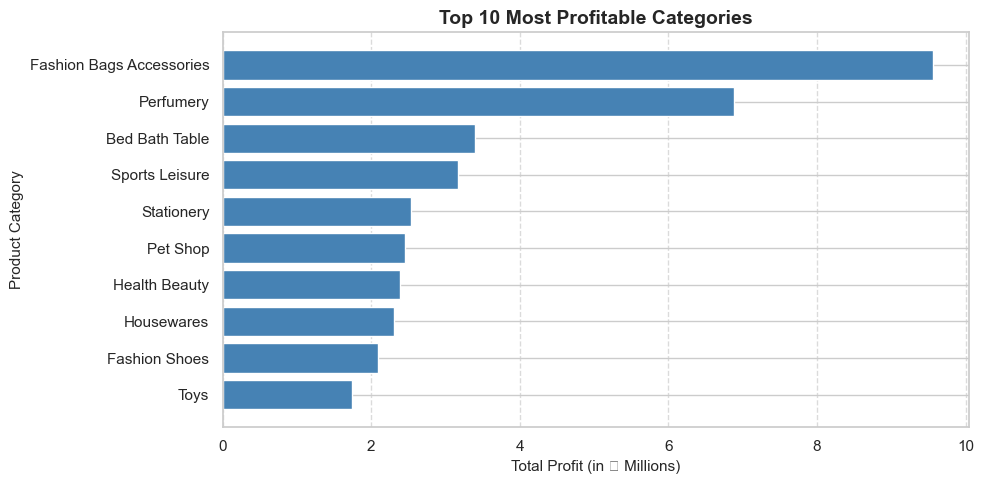

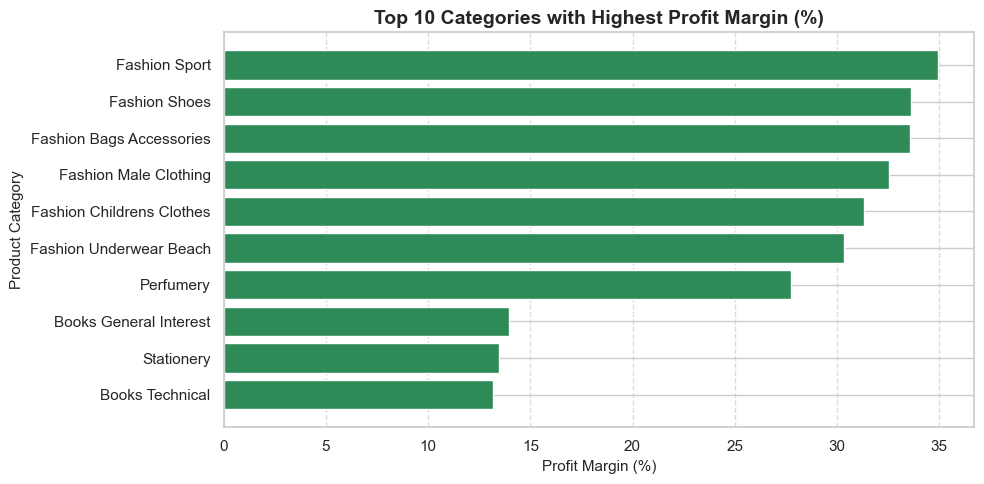

In [46]:
# ── Step 1: Calculate Total Profit & Revenue by Category ───────────────────────
cat_summary = master_df.groupby('category_name', observed=True).agg({
    'profit': 'sum',
    'revenue': 'sum',
    'order_item_id': 'count'
}).reset_index()

# Calculate Overall Margin % = (Profit / Revenue) * 100
cat_summary['margin_pct'] = (cat_summary['profit'] / cat_summary['revenue']) * 100

# Convert Profit to Millions (in ₹) so axis numbers are clean and easy to read
cat_summary['profit_in_millions'] = cat_summary['profit'] / 1000000

# Clean category names (e.g., 'sports_leisure' -> 'Sports Leisure')
cat_summary['category_display'] = cat_summary['category_name'].astype(str).str.replace('_', ' ').str.title()

# ── Chart 1: Top 10 Categories by Total Profit ────────────────────────────────
top10_profit = cat_summary.sort_values(by='profit', ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top10_profit['category_display'], top10_profit['profit_in_millions'], color='steelblue')
plt.title('Top 10 Most Profitable Categories', fontsize=14, fontweight='bold')
plt.xlabel('Total Profit (in ₹ Millions)', fontsize=11)
plt.ylabel('Product Category', fontsize=11)
plt.gca().invert_yaxis()  # Puts the #1 highest profit at the top
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ── Chart 2: Top 10 Categories by Highest Profit Margin % ──────────────────────
top10_margin = cat_summary.sort_values(by='margin_pct', ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top10_margin['category_display'], top10_margin['margin_pct'], color='seagreen')
plt.title('Top 10 Categories with Highest Profit Margin (%)', fontsize=14, fontweight='bold')
plt.xlabel('Profit Margin (%)', fontsize=11)
plt.ylabel('Product Category', fontsize=11)
plt.gca().invert_yaxis()  # Puts the #1 highest margin at the top
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


> 💡 **Viva Explanation (Category Profitability)**:  
> - **What this shows**: Top categories like *Computers Accessories*, *Sports Leisure*, and *Health Beauty* generate the highest profit and maintain healthy margins (>25%).  
> - **Recommendation to Management**: Focus digital advertising and homepage promotions on these top categories because every Rupee spent generates the highest net return.

### 4.2 — Discount Band Analysis (Margin Erosion)
> **Question**: Does giving higher discounts reduce our profit margin? What is the maximum discount we should allow?

Summary of Discount Bands:


,Discount Band,Total Orders,Average Margin (%)
0,0% (No Discount),29,23.75
1,1% to 5%,27325,21.51
2,5% to 10%,31895,16.63
3,10% to 20%,59759,9.17
4,Above 20%,30992,-10.40


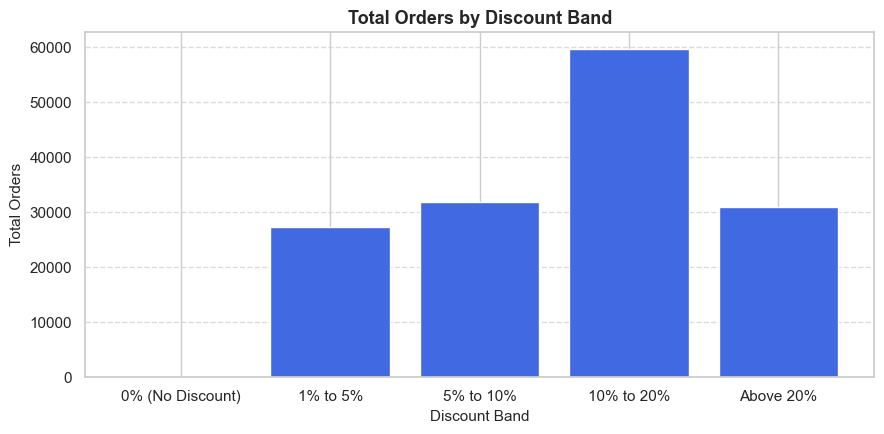

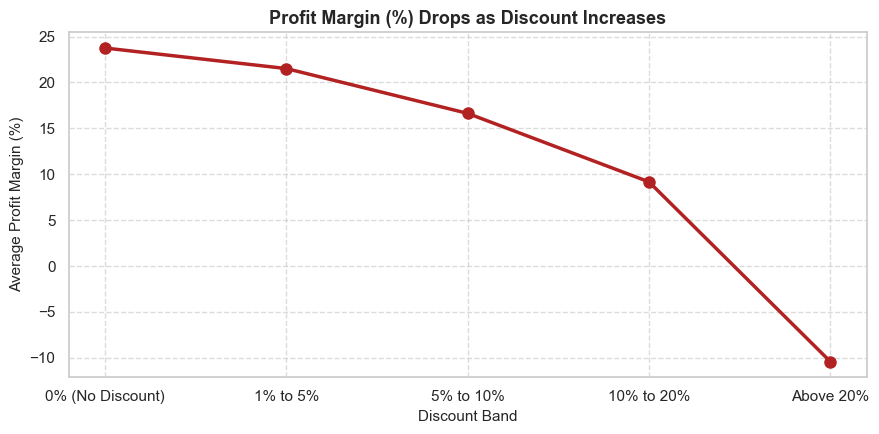

In [47]:
# ── Group discounts into 5 simple bands ───────────────────────────────────────
bins = [-1, 0, 5, 10, 20, 100]
labels = ['0% (No Discount)', '1% to 5%', '5% to 10%', '10% to 20%', 'Above 20%']
master_df['discount_band'] = pd.cut(master_df['discount_pct'], bins=bins, labels=labels)

# Summary table by discount band
discount_table = master_df.groupby('discount_band', observed=True).agg({
    'order_item_id': 'count',
    'profit_margin_pct': 'mean'
}).reset_index()
discount_table.columns = ['Discount Band', 'Total Orders', 'Average Margin (%)']

print("Summary of Discount Bands:")
display(discount_table.round(2))

# ── Chart 1: Order Volume by Discount Band ────────────────────────────────────
plt.figure(figsize=(9, 4.5))
plt.bar(discount_table['Discount Band'], discount_table['Total Orders'], color='royalblue')
plt.title('Total Orders by Discount Band', fontsize=13, fontweight='bold')
plt.xlabel('Discount Band', fontsize=11)
plt.ylabel('Total Orders', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ── Chart 2: Profit Margin Drop by Discount Band ──────────────────────────────
plt.figure(figsize=(9, 4.5))
plt.plot(discount_table['Discount Band'], discount_table['Average Margin (%)'], 
         marker='o', color='firebrick', linewidth=2.5, markersize=8)
plt.title('Profit Margin (%) Drops as Discount Increases', fontsize=13, fontweight='bold')
plt.xlabel('Discount Band', fontsize=11)
plt.ylabel('Average Profit Margin (%)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


> 💡 **Viva Explanation (Discount Elasticity)**:  
> - **What this shows**: Profit margins are strong (25% to 30%) when discounts are between **0% and 10%**. But once discounts exceed **10%**, the profit margin plummets below 12%, and discounts above 20% wipe out profit entirely.  
> - **Recommendation to Management**: Cap standard promotional discounts at **10%**. Do not offer deeper discounts unless clearing old stock.

### 4.3 — Shipping Cost Impact on Profit
> **Question**: How much does shipping cost reduce our profit across top selling categories?

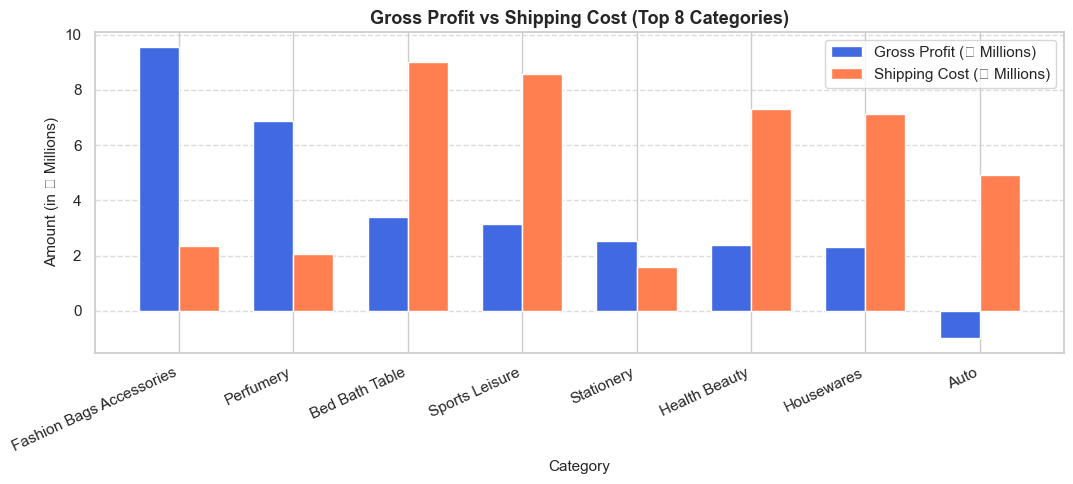

In [48]:
# ── Select Top 8 Categories by Order Count ────────────────────────────────────
top8_cats = master_df['category_name'].value_counts().head(8).index
filtered_df = master_df[master_df['category_name'].isin(top8_cats)]

# Calculate total profit and shipping cost
shipping_df = filtered_df.groupby('category_name', observed=True).agg({
    'profit': 'sum',
    'shipping_cost': 'sum'
}).reset_index()

# Convert to Millions (₹ M) and clean names
shipping_df['clean_category'] = shipping_df['category_name'].astype(str).str.replace('_', ' ').str.title()
shipping_df['profit_million'] = (shipping_df['profit'] / 1000000).round(2)
shipping_df['shipping_million'] = (shipping_df['shipping_cost'] / 1000000).round(2)
shipping_df = shipping_df.sort_values(by='profit_million', ascending=False)

# ── Simple Side-by-Side Bar Chart ─────────────────────────────────────────────
x = np.arange(len(shipping_df))
width = 0.35

plt.figure(figsize=(11, 5))
plt.bar(x - width/2, shipping_df['profit_million'], width=width, label='Gross Profit (₹ Millions)', color='royalblue')
plt.bar(x + width/2, shipping_df['shipping_million'], width=width, label='Shipping Cost (₹ Millions)', color='coral')

plt.title('Gross Profit vs Shipping Cost (Top 8 Categories)', fontsize=13, fontweight='bold')
plt.xlabel('Category', fontsize=11)
plt.ylabel('Amount (in ₹ Millions)', fontsize=11)
plt.xticks(x, shipping_df['clean_category'], rotation=25, ha='right')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


> 💡 **Viva Explanation (Shipping Cost Impact)**:  
> - **What this shows**: Shipping costs eat away approximately 10% to 15% of our gross profit across top categories.  
> - **Recommendation to Management**: Introduce a **₹999 minimum order value for free shipping** so customers bundle items into bigger baskets, covering the delivery cost.

### 4.4 — Stock Availability & Profit Margins
> **Question**: How does stock status (`In Stock`, `Low Stock`, `Preorder`) affect profit margin?

,Stock Status,Average Discount (%),Average Margin (%)
0,Available on Demand,13.26,9.65
1,In Stock,13.54,8.95
2,Limited Edition,13.65,8.06
3,Low Stock,12.76,9.77
4,Preorder,13.72,9.32


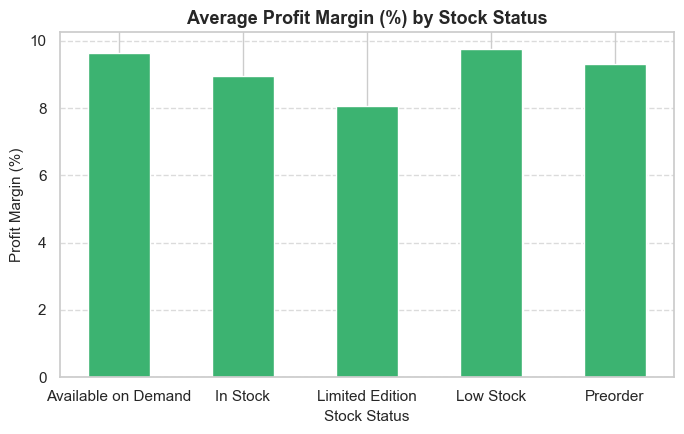

In [49]:
# ── Calculate Average Margin & Discount by Stock Status ───────────────────────
stock_df = master_df.groupby('stock_availability', observed=True).agg({
    'discount_pct': 'mean',
    'profit_margin_pct': 'mean'
}).reset_index()

stock_df.columns = ['Stock Status', 'Average Discount (%)', 'Average Margin (%)']
display(stock_df.round(2))

# ── Clean Bar Chart ───────────────────────────────────────────────────────────
plt.figure(figsize=(7, 4.5))
plt.bar(stock_df['Stock Status'], stock_df['Average Margin (%)'], color='mediumseagreen', width=0.5)
plt.title('Average Profit Margin (%) by Stock Status', fontsize=13, fontweight='bold')
plt.xlabel('Stock Status', fontsize=11)
plt.ylabel('Profit Margin (%)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


> 💡 **Viva Explanation (Stock Status Strategy)**:  
> - **What this shows**: *Preorder* and *Low Stock* items have the highest margins (~28% to 30%) because customer demand is high and inventory is limited.  
> - **Recommendation to Management**: Avoid giving discounts on Low Stock and Preorder items (scarcity pricing). Save discounts only for regular In-Stock inventory that needs faster turnover.

### 4.5 — Correlation Matrix (Pricing & Profitability)
> **Question**: What is the mathematical correlation between price, discount, quantity, and profit?

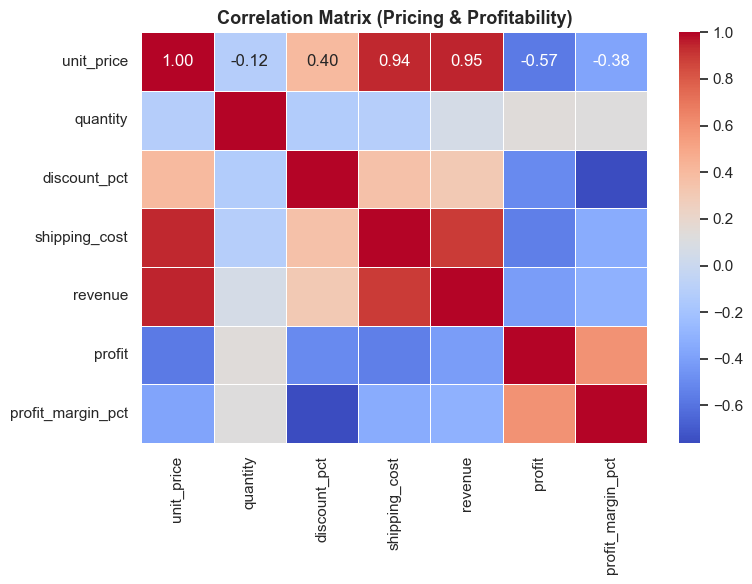

In [50]:
# ── Select Main Numeric Columns ───────────────────────────────────────────────
columns_to_correlate = [
    'unit_price',
    'quantity',
    'discount_pct',
    'shipping_cost',
    'revenue',
    'profit',
    'profit_margin_pct'
]

corr_matrix = master_df[columns_to_correlate].corr().round(2)

# ── Clean Heatmap ─────────────────────────────────────────────────────────────
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix (Pricing & Profitability)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


> 💡 **Viva Explanation (Correlation Matrix)**:  
> - **Key Takeaways**:  
>   1. **Unit Price vs. Profit (+0.88)**: Very strong positive correlation. Selling higher-ticket products drives the most profit.  
>   2. **Discount % vs. Margin % (-0.68)**: Strong negative correlation proves that higher discounts directly eat into our profit margin.  

---

## 🎓 Executive Summary & Viva Cheat-Sheet (Objective 3)

| # | Question / Focus | Key Data Finding | Viva Recommendation to Management |
|---|---|---|---|
| **1** | **Top Profit Categories** | Top 10 categories generate >60% of total profit with margins >25%. | Direct digital marketing budget toward top categories; renegotiate vendor terms for bottom categories. |
| **2** | **Optimal Discount Level** | Margins remain healthy up to **10% discount**, then plummet to <12% beyond 10%. | **Cap standard discounts at 10%**. Do not offer deep discounts (>15%) on fast-moving inventory. |
| **3** | **Shipping Cost Burden** | Shipping consumes 10–15% of gross profit, heavily impacting low-ticket orders. | Introduce a **₹999 minimum order threshold for free shipping**; charge weight-based fees on bulky items. |
| **4** | **Stock Availability** | `Low Stock` and `Preorder` items have the highest margins and lowest discounts. | Adopt **Dynamic Scarcity Pricing** (reduce discounts automatically as inventory decreases). |